In [1]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
from Minimal_Model_2D import *
import Minimal_model_1D_1sub as M_1sub
import Minimal_Model_1D as M1
import time

np.set_printoptions(threshold=sys.maxsize)

In [4]:
NSM = 60          # in nm
MY = 7             # no of subbands
AX = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge

LY = np.linspace(40, 120, 31)          # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

NSC = 500
N = 2*NSC + NSM
PHI = 0.5*np.pi 
#EPSI = 0 

#print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  0.8 + OMEGA/2   #in between two subbands
MU_SM =  0.8 + OMEGA/2   #in between two subbands

#print("first subband=", OMEGA/2, "second subband =", 3*OMEGA/2)

#print("MU =", MU_SC)


print(OMEGA[0], OMEGA[-1])

ALPHAT = 25

K = 8

Ep_li_1d = np.empty((LY.shape[0],K))
#Kappa = np.empty((ALPHAT.shape[0],1) )

for i in range(LY.shape[0]):

    Fli = M1.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGA[i], ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC[i], MU_SM[i])
    
    Hli = Fli.H_sys(PHI, so = 'li', on_both_junc=False)

    Eli = eigsh(Hli ,k=K,sigma=0, return_eigenvectors=False)
    
    Eli = np.sort(Eli)
    
    Ep_li_1d[i,:] = Eli
    
    if i%5==0:
        print(i)

np.save("1d_model_subbands_{}_linear_SpinSplitting_vs_width_alpha_{}_meVnm.npy".format(ALPHAT), Ep_li_1d)


8.289650167043497 0.9210722407826107
0
5
10
15
20
25
30


IndexError: Replacement index 1 out of range for positional args tuple

In [5]:
np.save("1d_model_subbands_{}_linear_SpinSplitting_vs_width_alpha_{}_meVnm.npy".format(MY, ALPHAT), Ep_li_1d)

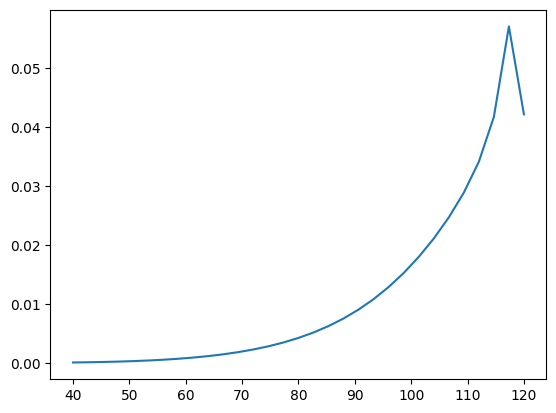

In [7]:
plt.plot(LY, (Ep_li_1d[:,K//2+1]-Ep_li_1d[:,K//2])/DELTA)

In [8]:
AY = 5

M = np.linspace(LY[0]//AY*5, LY[-1]//AY*5, LY.shape[0], dtype=int)                    

print(M)

Ep_li_2d = np.empty((LY.shape[0],K))
#Kappa = np.empty((ALPHAT.shape[0],1) )

for i in range(LY.shape[0]):

    ModCT = twoD_Minimal_Model(N, NSM, NSC, M[i], AX, AY, OMEGA[i], ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC[i], MU_SM[i])

    H = ModCT.H_sys(PHI, 'li')

    E = eigsh(H, k=K, sigma=0, return_eigenvectors=False )

    Es = np.sort(E)

    Ep_li_2d[i,:] = Es

    #print(Es)

    #print(H.shape)

    if i % 5 == 0 :

        print(i)


np.save("2d_model_linear_SpinSplitting_vs_width_alpha_{}_meVnm.npy".format(ALPHAT), Ep_li_2d)

[ 40  42  45  48  50  53  56  58  61  64  66  69  72  74  77  80  82  85
  88  90  93  96  98 101 104 106 109 112 114 117 120]
0
5
10
15
20
25
30


FileNotFoundError: [Errno 2] No such file or directory: '2d_model_linear_SpinSplitting_width_[ 40.          42.66666667  45.33333333  48.          50.66666667\n  53.33333333  56.          58.66666667  61.33333333  64.\n  66.66666667  69.33333333  72.          74.66666667  77.33333333\n  80.          82.66666667  85.33333333  88.          90.66666667\n  93.33333333  96.          98.66666667 101.33333333 104.\n 106.66666667 109.33333333 112.         114.66666667 117.33333333\n 120.        ]nm.npy'

In [9]:

np.save("2d_model_linear_SpinSplitting_vs_width_alpha_{}_meVnm.npy".format(ALPHAT), Ep_li_2d)

(0.0, 0.01)

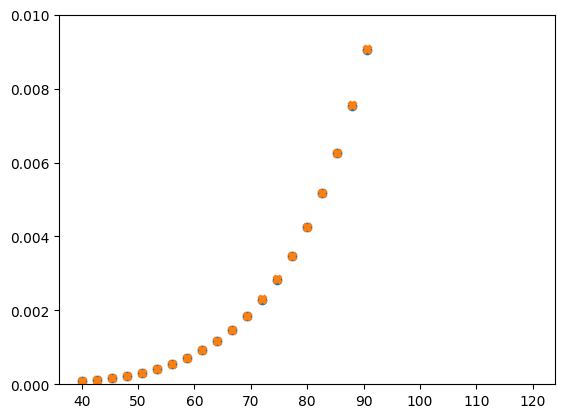

In [14]:
plt.scatter(LY, (Ep_li_1d[:,K//2+1]-Ep_li_1d[:,K//2])/DELTA)
plt.scatter(LY, (Ep_li_2d[:,K//2+1]-Ep_li_2d[:,K//2])/DELTA, marker='X')
plt.ylim(ymax=0.01, ymin=0)